In [23]:
import numpy as np
import torch
import torch.nn as nn
from dataclasses import dataclass
from typing import Callable, Optional
import matplotlib.pyplot as plt
import math
np.random.seed(0)
torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [24]:
!mkdir linear
!mkdir non_linear
!gdown --fuzzy "https://drive.google.com/uc?export=download&id=1zsdK2tTfrzuE5jL9p8YWaCah7uX-4x8f"
!mv /kaggle/working/ckpt_50000.pt linear

!gdown --fuzzy "https://drive.google.com/uc?export=download&id=1FIUIQ10qhkKWG1y_invJwsyScWa9XA9S"
!mv /kaggle/working/ckpt_50000.pt non_linear

mkdir: cannot create directory ‘linear’: File exists
mkdir: cannot create directory ‘non_linear’: File exists
Downloading...
From (original): https://drive.google.com/uc?id=1zsdK2tTfrzuE5jL9p8YWaCah7uX-4x8f
From (redirected): https://drive.google.com/uc?id=1zsdK2tTfrzuE5jL9p8YWaCah7uX-4x8f&confirm=t&uuid=9482734c-b7f4-4fcb-ab7d-177a8eced558
To: /kaggle/working/ckpt_50000.pt
100%|██████████████████████████████████████| 1.49G/1.49G [00:21<00:00, 69.8MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1FIUIQ10qhkKWG1y_invJwsyScWa9XA9S
From (redirected): https://drive.google.com/uc?id=1FIUIQ10qhkKWG1y_invJwsyScWa9XA9S&confirm=t&uuid=b2aca3ad-ccc0-48a8-af21-782acbcd1859
To: /kaggle/working/ckpt_50000.pt
100%|██████████████████████████████████████| 1.49G/1.49G [00:30<00:00, 49.1MB/s]


In [25]:
""" TAKEN FRON THE karpathy/nanogpt repository with modifications at the Query.
Full definition of a GPT Language Model, all of it in this single file.
References:
1) the official GPT-2 TensorFlow implementation released by OpenAI:
https://github.com/openai/gpt-2/blob/master/src/model.py
2) huggingface/transformers PyTorch implementation:
https://github.com/huggingface/transformers/blob/main/src/transformers/models/gpt2/modeling_gpt2.py
"""

import math
import inspect
from dataclasses import dataclass

import torch
import torch.nn as nn
from torch.nn import functional as F

class LayerNorm(nn.Module):
    """ LayerNorm but with an optional bias. PyTorch doesn't support simply bias=False """

    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None

    def forward(self, input):
        return F.layer_norm(input, self.weight.shape, self.weight, self.bias, 1e-5)

class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.num_heads == 0
        self.config = config
        # key, query, value projections for all heads, but in a batch
        if self.config.query_mode in ["identity", "residual_gelu"]:
            # reduced GPT-2 style, as per our paper
            # so we only have 2 * n_embd weights in total, instead of 3 * n_embd
            self.c_attn = nn.Linear(config.n_embd, 2 * config.n_embd, bias=config.bias)
        elif self.config.query_mode in ["residual", "original"]:
            # original query weights, with modifications on the application
            self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        # regularization
        if self.config.query_mode == "residual_gelu":
            self.residual_rmsnorm_input = nn.RMSNorm(config.n_embd, eps=1e-5)
            self.residual_layernorm_output = LayerNorm(config.n_embd, bias=config.bias)
            self.residual_in = nn.Linear(config.n_embd, config.n_embd//2, bias=config.bias)
            self.residual_out = nn.Linear(config.n_embd//2, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.num_heads = config.num_heads
        self.n_embd = config.n_embd
        self.dropout = config.dropout
        self.mlp_hidden_size = config.mlp_hidden_size
        # flash attention make GPU go brrrrr but support is only in PyTorch >= 2.0
        self.flash = hasattr(torch.nn.functional, 'scaled_dot_product_attention')
        self.config = config
        if not self.flash:
            print("WARNING: using slow attention. Flash Attention requires PyTorch >= 2.0")
            # causal mask to ensure that attention is only applied to the left in the input sequence
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                        .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)

        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        if self.config.query_mode in ["identity","residual_gelu"]:
            k, v = self.c_attn(x).split(self.n_embd, dim=2)
            if self.config.query_mode == "identity":
                q = x
            elif self.config.query_mode == "residual_gelu":
                q = x + self.residual_layernorm_output(self.residual_out(F.gelu(self.residual_in(self.residual_rmsnorm_input(x)))))
        else:  # original, residual
            q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
            if self.config.query_mode == "residual":
                q = x + q
                # else "original": q stays as-is

        q = q.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)
        k = k.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.num_heads, C // self.num_heads).transpose(1, 2) # (B, nh, T, hs)

        # causal self-attention; Self-attend: (B, nh, T, hs) x (B, nh, hs, T) -> (B, nh, T, T)
        if self.flash:
            # efficient attention using Flash Attention CUDA kernels
            y = torch.nn.functional.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0, is_causal=True, scale = self.config.scale)
        else:
            # manual implementation of attention
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side

        # output projection
        y = self.resid_dropout(self.c_proj(y))
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, config.mlp_hidden_size, bias=config.bias)
        self.gelu    = nn.GELU()
        self.c_proj  = nn.Linear(config.mlp_hidden_size, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)
        self.mlp_hidden_size = config.mlp_hidden_size
        self.normalizing_coef = 1.0 #weirdly the model in our try diverged with: math.sqrt(4*config.n_embd/config.mlp_hidden_size)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        x = self.dropout(x)
        return x*self.normalizing_coef

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = LayerNorm(config.n_embd, bias=config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = LayerNorm(config.n_embd, bias=config.bias)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50304
    n_layer: int = 12
    num_heads: int = 12
    n_embd: int = 768
    tie_weights: bool = True
    head_size: int = 64
    dropout: float = 0.0
    batch_size: int = 16
    accumulation_size: int = 30
    bias: bool = False
    scale: float = math.sqrt(1/head_size)
    query_mode: str = "original"  # "original", "identity", "residual", "residual_gelu"
    learning_rate: float = 6e-4
    weight_decay: float = 1e-1
    beta1: float = 0.9
    beta2: float = 0.95
    grad_clip: float = 1.0
    decay_lr: bool = True
    warmup_iters: int = 2000
    lr_decay_iters: int = 600000
    min_lr: float = 6e-5
    mlp_hidden_size: int = 4*768
    save_checkpoint_steps: list = None
    max_iters: int = 600000

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.vocab_size is not None
        assert config.block_size is not None
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            drop = nn.Dropout(config.dropout),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = LayerNorm(config.n_embd, bias=config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        # with weight tying when using torch.compile() some warnings get generated:
        # "UserWarning: functional_call was passed multiple values for tied weights.
        # This behavior is deprecated and will be an error in future versions"
        # not 100% sure what this is, so far seems to be harmless. TODO investigate
        if config.tie_weights:
            self.transformer.wte.weight = self.lm_head.weight # https://paperswithcode.com/method/weight-tying

        # init all weights
        self.apply(self._init_weights)
        # apply special scaled init to the residual projections, per GPT-2 paper
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                torch.nn.init.normal_(p, mean=0.0, std=0.02/math.sqrt(2 * config.n_layer))

        # report number of parameters
        print("number of parameters: %.2fM" % (self.get_num_params()/1e6,))

    def get_num_params(self, non_embedding=True):
        """
        Return the number of parameters in the model.
        For non-embedding count (default), the position embeddings get subtracted.
        The token embeddings would too, except due to the parameter sharing these
        params are actually used as weights in the final layer, so we include them.
        """
        n_params = sum(p.numel() for p in self.parameters())
        if non_embedding:
            n_params -= self.transformer.wpe.weight.numel()
        return n_params

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        device = idx.device
        b, t = idx.size()
        assert t <= self.config.block_size, f"Cannot forward sequence of length {t}, block size is only {self.config.block_size}"
        pos = torch.arange(0, t, dtype=torch.long, device=device) # shape (t)

        # forward the GPT model itself
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (b, t, n_embd)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (t, n_embd)
        x = self.transformer.drop(tok_emb + pos_emb)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            # if we are given some desired targets also calculate the loss
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
        else:
            # inference-time mini-optimization: only forward the lm_head on the very last position
            logits = self.lm_head(x[:, [-1], :]) # note: using list [-1] to preserve the time dim
            loss = None

        return logits, loss

    def crop_block_size(self, block_size):
        # model surgery to decrease the block size if necessary
        # e.g. we may load the GPT2 pretrained model checkpoint (block size 1024)
        # but want to use a smaller block size for some smaller, simpler model
        assert block_size <= self.config.block_size
        self.config.block_size = block_size
        self.transformer.wpe.weight = nn.Parameter(self.transformer.wpe.weight[:block_size])
        for block in self.transformer.h:
            if hasattr(block.attn, 'bias'):
                block.attn.bias = block.attn.bias[:,:,:block_size,:block_size]

    @classmethod
    def from_pretrained(cls, model_type, override_args=None):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        override_args = override_args or {} # default to empty dict
        # only dropout can be overridden see more notes below
        assert all(k == 'dropout' for k in override_args)
        from transformers import GPT2LMHeadModel
        print("loading weights from pretrained gpt: %s" % model_type)

        # n_layer, num_heads and n_embd are determined from model_type
        config_args = {
            'gpt2':         dict(n_layer=12, num_heads=12, n_embd=768),  # 124M params
            'gpt2-medium':  dict(n_layer=24, num_heads=16, n_embd=1024), # 350M params
            'gpt2-large':   dict(n_layer=36, num_heads=20, n_embd=1280), # 774M params
            'gpt2-xl':      dict(n_layer=48, num_heads=25, n_embd=1600), # 1558M params
        }[model_type]
        print("forcing vocab_size=50257, block_size=1024, bias=True")
        config_args['vocab_size'] = 50257 # always 50257 for GPT model checkpoints
        config_args['block_size'] = 1024 # always 1024 for GPT model checkpoints
        config_args['bias'] = True # always True for GPT model checkpoints
        # we can override the dropout rate, if desired
        if 'dropout' in override_args:
            print(f"overriding dropout rate to {override_args['dropout']}")
            config_args['dropout'] = override_args['dropout']
        # create a from-scratch initialized minGPT model
        config = GPTConfig(**config_args)
        print(config)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')] # discard this mask / buffer, not a param

        # init a huggingface/transformers model
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()

        # copy while ensuring all of the parameters are aligned and match in names and shapes
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')] # ignore these, just a buffer
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')] # same, just the mask (buffer)
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        # basically the openai checkpoints use a "Conv1D" module, but we only want to use a vanilla Linear
        # this means that we have to transpose these weights when we import them
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                # special treatment for the Conv1D weights we need to transpose
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                # vanilla copy over the other parameters
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        return model

    def configure_optimizers(self, weight_decay, learning_rate, betas, device_type):
        weight_decay = self.config.weight_decay
        print("weight decay: ", weight_decay)
        # start with all of the candidate parameters
        param_dict = {pn: p for pn, p in self.named_parameters()}
        # filter out those that do not require grad
        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
        # create optim groups. Any parameters that is 2D will be weight decayed, otherwise no.
        # i.e. all weight tensors in matmuls + embeddings decay, all biases and layernorms don't.
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        num_decay_params = sum(p.numel() for p in decay_params)
        num_nodecay_params = sum(p.numel() for p in nodecay_params)
        print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
        print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
        # Create AdamW optimizer and use the fused version if it is available
        fused_available = 'fused' in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == 'cuda'
        extra_args = dict(fused=True) if use_fused else dict()
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=betas, **extra_args)
        print(f"using fused AdamW: {use_fused}")

        return optimizer

    def estimate_mfu(self, fwdbwd_per_iter, dt):
        """ estimate model flops utilization (MFU) in units of A100 bfloat16 peak FLOPS """
        # first estimate the number of flops we do per iteration.
        # see PaLM paper Appendix B as ref: https://arxiv.org/abs/2204.02311
        N = self.get_num_params()
        cfg = self.config
        L, H, Q, T = cfg.n_layer, cfg.num_heads, cfg.n_embd//cfg.num_heads, cfg.block_size
        flops_per_token = 6*N + 12*L*H*Q*T
        flops_per_fwdbwd = flops_per_token * T
        flops_per_iter = flops_per_fwdbwd * fwdbwd_per_iter
        # express our flops throughput as ratio of A100 bfloat16 peak flops
        flops_achieved = flops_per_iter * (1.0/dt) # per second
        flops_promised = 312e12 # A100 GPU bfloat16 peak flops is 312 TFLOPS
        mfu = flops_achieved / flops_promised
        return mfu

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        Take a conditioning sequence of indices idx (LongTensor of shape (b,t)) and complete
        the sequence max_new_tokens times, feeding the predictions back into the model each time.
        Most likely you'll want to make sure to be in model.eval() mode of operation for this.
        """
        for _ in range(max_new_tokens):
            # if the sequence context is growing too long we must crop it at block_size
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            # forward the model to get the logits for the index in the sequence
            logits, _ = self(idx_cond)
            # pluck the logits at the final step and scale by desired temperature
            logits = logits[:, -1, :] / temperature
            # optionally crop the logits to only the top k options
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            # apply softmax to convert logits to (normalized) probabilities
            probs = F.softmax(logits, dim=-1)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)
            # append sampled index to the running sequence and continue
            idx = torch.cat((idx, idx_next), dim=1)

        return idx

In [26]:
class Config:
    # Model architecture
    block_size= 1024
    vocab_size= 50304
    n_layer= 12
    num_heads= 12
    n_embd= 768
    head_size= 64
    mlp_hidden_size= 768 * 4

    # Weight configuration
    tie_weights= True

    # Query mode: "original", "identity", "residual", "residual_gelu"
    query_mode= "original"

    # Regularization
    dropout= 0.0
    bias= False

    # Training batch configuration
    batch_size =12
    accumulation_size= 40

    # Attention scale
    scale= 1/(math.sqrt(768//12))

    # Optimizer settings
    learning_rate= 6e-4
    weight_decay= 0.1
    beta1= 0.9
    beta2= 0.95
    grad_clip= 1.0

    # Learning rate schedule
    decay_lr= True
    warmup_iters= 2000
    lr_decay_iters= 60002
    min_lr = 6e-5

    # Checkpoint and early stopping
    save_checkpoint_steps= [50000, 100000, 105000]
    max_iters= 60002


model_linear=GPT(Config()).to(device)


checkpoint = torch.load("/kaggle/working/linear/ckpt_50000.pt", map_location=device)


state_dict = checkpoint if not isinstance(checkpoint, dict) else checkpoint.get('model', checkpoint)


new_state_dict = {}
for k, v in state_dict.items():
    new_key = k
    if not k.startswith('transformer.'):
        new_key = 'transformer.' + k
        
    new_state_dict[new_key] = v


model_linear.load_state_dict(new_state_dict, strict=False)


for name, module in model_linear.named_modules():
        print(f"{name}: {type(module).__name__}")



number of parameters: 123.59M
: GPT
transformer: ModuleDict
transformer.wte: Embedding
transformer.wpe: Embedding
transformer.drop: Dropout
transformer.h: ModuleList
transformer.h.0: Block
transformer.h.0.ln_1: LayerNorm
transformer.h.0.attn: CausalSelfAttention
transformer.h.0.attn.c_attn: Linear
transformer.h.0.attn.c_proj: Linear
transformer.h.0.attn.attn_dropout: Dropout
transformer.h.0.attn.resid_dropout: Dropout
transformer.h.0.ln_2: LayerNorm
transformer.h.0.mlp: MLP
transformer.h.0.mlp.c_fc: Linear
transformer.h.0.mlp.gelu: GELU
transformer.h.0.mlp.c_proj: Linear
transformer.h.0.mlp.dropout: Dropout
transformer.h.1: Block
transformer.h.1.ln_1: LayerNorm
transformer.h.1.attn: CausalSelfAttention
transformer.h.1.attn.c_attn: Linear
transformer.h.1.attn.c_proj: Linear
transformer.h.1.attn.attn_dropout: Dropout
transformer.h.1.attn.resid_dropout: Dropout
transformer.h.1.ln_2: LayerNorm
transformer.h.1.mlp: MLP
transformer.h.1.mlp.c_fc: Linear
transformer.h.1.mlp.gelu: GELU
transfor

In [27]:
class Config:
    # Model architecture
    block_size= 1024
    vocab_size= 50304
    n_layer= 12
    num_heads= 12
    n_embd= 768
    head_size= 64
    mlp_hidden_size= 768 * 4

    # Weight configuration
    tie_weights= True

    # Query mode: "original", "identity", "residual", "residual_gelu"
    query_mode= "residual_gelu"

    # Regularization
    dropout= 0.0
    bias= False

    # Training batch configuration
    batch_size =12
    accumulation_size= 40

    # Attention scale
    scale= 1/(math.sqrt(768//12))

    # Optimizer settings
    learning_rate= 1.5e-3
    weight_decay= 2**-5
    beta1= 0.9
    beta2= 0.95
    grad_clip= 1.0

    # Learning rate schedule
    decay_lr= True
    warmup_iters= 2000
    lr_decay_iters= 60002
    min_lr = 4e-5

    # Checkpoint and early stopping
    save_checkpoint_steps= [50000, 100000, 105000]
    max_iters= 60002


model_non_linear=GPT(Config()).to(device)


checkpoint = torch.load("/kaggle/working/non_linear/ckpt_50000.pt", map_location=device)


state_dict = checkpoint if not isinstance(checkpoint, dict) else checkpoint.get('model', checkpoint)


new_state_dict = {}
for k, v in state_dict.items():
    new_key = k
    if not k.startswith('transformer.'):
        new_key = 'transformer.' + k
        
    new_state_dict[new_key] = v


model_non_linear.load_state_dict(new_state_dict, strict=False)


for name, module in model_non_linear.named_modules():
        print(f"{name}: {type(module).__name__}")



number of parameters: 123.61M
: GPT
transformer: ModuleDict
transformer.wte: Embedding
transformer.wpe: Embedding
transformer.drop: Dropout
transformer.h: ModuleList
transformer.h.0: Block
transformer.h.0.ln_1: LayerNorm
transformer.h.0.attn: CausalSelfAttention
transformer.h.0.attn.c_attn: Linear
transformer.h.0.attn.c_proj: Linear
transformer.h.0.attn.residual_rmsnorm_input: RMSNorm
transformer.h.0.attn.residual_layernorm_output: LayerNorm
transformer.h.0.attn.residual_in: Linear
transformer.h.0.attn.residual_out: Linear
transformer.h.0.attn.attn_dropout: Dropout
transformer.h.0.attn.resid_dropout: Dropout
transformer.h.0.ln_2: LayerNorm
transformer.h.0.mlp: MLP
transformer.h.0.mlp.c_fc: Linear
transformer.h.0.mlp.gelu: GELU
transformer.h.0.mlp.c_proj: Linear
transformer.h.0.mlp.dropout: Dropout
transformer.h.1: Block
transformer.h.1.ln_1: LayerNorm
transformer.h.1.attn: CausalSelfAttention
transformer.h.1.attn.c_attn: Linear
transformer.h.1.attn.c_proj: Linear
transformer.h.1.attn.r

In [28]:
def extract_model_features(model, layer_idx, data_loader, n_embd, max_batches=20, device=device):
    q_store, k_store, v_store = [], [], []

    attn_module = model.transformer.h[layer_idx].attn

    def attn_hook(_m, _i, out):
        x = _i[0]  # input to c_attn, i.e. ln_1(x_block) -- same x used to build q,k,v
        if attn_module.config.query_mode in ["identity", "residual_gelu"]:
            k, v = out.split(n_embd, dim=2)
            if attn_module.config.query_mode == "identity":
                q = x
            else:  # residual_gelu
                q = x + attn_module.residual_layernorm_output(
                    attn_module.residual_out(
                        torch.nn.functional.gelu(
                            attn_module.residual_in(attn_module.residual_rmsnorm_input(x))
                        )
                    )
                )
        else:  # original, residual
            q, k, v = out.split(n_embd, dim=2)
            if attn_module.config.query_mode == "residual":
                q = x + q

        q_store.append(q.detach().reshape(-1, n_embd).cpu())
        k_store.append(k.detach().reshape(-1, n_embd).cpu())
        v_store.append(v.detach().reshape(-1, n_embd).cpu())

    h = attn_module.c_attn.register_forward_hook(attn_hook)

    model.eval()
    with torch.no_grad():
        for i, batch in enumerate(data_loader):
            if max_batches is not None and i >= max_batches:
                break
            x = torch.as_tensor(batch["input_ids"]).to(device)
            model(x)

    h.remove()

    f_arr = torch.cat(q_store).numpy()   # f(x) = query -- nonlinear only in residual_gelu
    p_arr = torch.cat(k_store).numpy()   # P(x) = key   -- always exactly linear
    q_arr = torch.cat(v_store).numpy()   # Q(x) = value -- always exactly linear
    return f_arr, p_arr, q_arr

In [29]:
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader
import torch


tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token 


raw_dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="test")


def tokenize_fn(examples):
    return tokenizer(examples["text"], truncation=True, max_length=1024, padding="max_length", return_tensors="pt")


tokenized_dataset = raw_dataset.map(tokenize_fn, batched=True, remove_columns=["text"])
tokenized_dataset.set_format(type="torch", columns=["input_ids"])


val_loader = DataLoader(tokenized_dataset, batch_size=4, shuffle=False)

In [30]:
from sklearn.covariance import LedoitWolf

def shrinkage_cov(X: np.ndarray):
    #Ledoit-Wolf shrinkage covariance estimate (also centers X).
    lw = LedoitWolf().fit(X)
    return lw.covariance_

def pinv_eig(S: np.ndarray, rel_cutoff: float = 1e-8):
    #Symmetric pseudo-inverse via eigendecomposition with a relative cutoff.
    S = 0.5 * (S + S.T)
    w, V = np.linalg.eigh(S)
    wmax = w.max() if w.max() > 0 else 1.0
    keep = w > rel_cutoff * wmax
    w_inv = np.zeros_like(w)
    w_inv[keep] = 1.0 / w[keep]
    return (V * w_inv) @ V.T

def eig_rank(S: np.ndarray, rel_cutoff: float = 1e-6):
    S = 0.5 * (S + S.T)
    w = np.linalg.eigvalsh(S)
    wmax = w.max() if w.max() > 0 else 1.0
    return int(np.sum(w > rel_cutoff * wmax))

def eig_rank_scaled(S: np.ndarray, reference_scale: float, rel_cutoff: float = 1e-3):
    """Rank via cutoff relative to an EXTERNAL reference (e.g. Sigma_ff's typical
    eigenvalue), not S's own max. Needed because Rf can be uniformly small — a
    self-relative cutoff always calls a uniformly-small matrix 'full rank'."""
    S = 0.5 * (S + S.T)
    w = np.linalg.eigvalsh(S)
    ref = reference_scale if reference_scale > 0 else 1.0
    return int(np.sum(w > rel_cutoff * ref))

def schur_complement_stats(F: np.ndarray, B: np.ndarray,
                            rel_cutoffs=(1e-3, 1e-4, 1e-6, 1e-8),
                            use_shrinkage: bool = False,
                            holdout_frac: float = 0.5,
                            seed: int = 0):
    #Fit Sigma_fb, Sigma_bb on a train split; evaluate Sigma_ff, R_f on held-out data.
    rng = np.random.default_rng(seed)
    N = F.shape[0]
    idx = rng.permutation(N)
    n_train = int(N * (1 - holdout_frac))
    tr, ev = idx[:n_train], idx[n_train:]

    Ftr, Btr = F[tr], B[tr]
    Fev, Bev = F[ev], B[ev]

    Fmean, Bmean = Ftr.mean(0), Btr.mean(0)
    Ftr_c, Btr_c = Ftr - Fmean, Btr - Bmean
    Fev_c, Bev_c = Fev - Fmean, Bev - Bmean  # center eval set with TRAIN mean (no leakage)

    if use_shrinkage:
        Sigma_bb = shrinkage_cov(Btr)
    else:
        Sigma_bb = np.cov(Btr_c, rowvar=False)
    Sigma_fb = (Ftr_c.T @ Btr_c) / (n_train - 1)

    Sigma_bb_pinv = pinv_eig(Sigma_bb)

    # affine least-squares predictor fit on TRAIN, coefficients:
    #   f_hat = Fmean + Sigma_fb @ Sigma_bb^+ @ (b - Bmean)
    W = Sigma_fb @ Sigma_bb_pinv  # (df, 2d) maps centered b -> predicted centered f

    # evaluate residual covariance on HELD-OUT data (this IS Rf, evaluated out-of-sample)
    Fev_hat_c = Bev_c @ W.T
    resid = Fev_c - Fev_hat_c
    Rf_holdout = np.cov(resid, rowvar=False)

    # also compute the "textbook" in-sample Rf directly from the Schur complement formula,
    # as an algebraic cross-check (should match an in-sample regression residual cov)
    Sigma_ff_tr = np.cov(Ftr_c, rowvar=False)
    Rf_insample = Sigma_ff_tr - Sigma_fb @ Sigma_bb_pinv @ Sigma_fb.T

    out = {
        "Sigma_bb": Sigma_bb,
        "Sigma_fb": Sigma_fb,
        "Rf_insample": Rf_insample,
        "Rf_holdout": Rf_holdout,
    }

    Sff_eval = np.cov(Fev_c, rowvar=False)
    Sff_ref = np.trace(Sff_eval) / Sff_eval.shape[0]   # mean eigenvalue, not max

    for cutoff in rel_cutoffs:
        out[f"rank_Sigma_bb@{cutoff:g}"] = eig_rank(Sigma_bb, cutoff)
        out[f"rank_Rf_insample@{cutoff:g}"] = eig_rank_scaled(Rf_insample, Sff_ref, cutoff)
        out[f"rank_Rf_holdout@{cutoff:g}"] = eig_rank_scaled(Rf_holdout, Sff_ref, cutoff)

    tr_Rf = np.trace(Rf_holdout)
    tr_Rf2 = np.trace(Rf_holdout @ Rf_holdout)
    tr_Sff = np.trace(np.cov(Fev_c, rowvar=False))
    out["nu_eff"] = float(tr_Rf ** 2 / tr_Rf2) if tr_Rf2 > 0 else 0.0
    out["nu_frac"] = float(tr_Rf / tr_Sff) if tr_Sff > 0 else 0.0
    return out

def permutation_null(F: np.ndarray, B: np.ndarray, n_perm: int = 20, **kwargs):
    #Baseline: shuffle F against B (breaks any true f<->b relationship) and recompute
    #nu_eff / nu_frac. This is the noise floor you'd see from pure estimation error even
    #under TRUE independence -- compare checkpoint results against this range.\"\"\"
    rng = np.random.default_rng(123)
    nu_effs, nu_fracs = [], []
    for i in range(n_perm):
        perm = rng.permutation(F.shape[0])
        stats = schur_complement_stats(F[perm], B, seed=i, **kwargs)
        nu_effs.append(stats["nu_eff"])
        nu_fracs.append(stats["nu_frac"])
    return {
        "nu_eff_null_mean": float(np.mean(nu_effs)), "nu_eff_null_std": float(np.std(nu_effs)),
        "nu_frac_null_mean": float(np.mean(nu_fracs)), "nu_frac_null_std": float(np.std(nu_fracs)),
    }

In [31]:
import torch.nn.functional as F

n_layers = model_linear.config.n_layer  # 12
max_batches = 5 
n_perm = 3
max_rows_for_stats = 20000
rng = np.random.default_rng(0)

layer_results = {}  # layer_results[L][checkpoint_name] = {**stats, **null}

for L in range(n_layers):
    F_lin, P_lin, Q_lin = extract_model_features(
        model_linear,
        L,
        val_loader,
        model_linear.config.n_embd,
        max_batches=max_batches
    )
    F_non, P_non, Q_non = extract_model_features(
        model_non_linear,
        L,
        val_loader,
        model_non_linear.config.n_embd,
        max_batches=max_batches
    )

    B_lin = np.concatenate([P_lin, Q_lin], axis=1)
    B_non = np.concatenate([P_non, Q_non], axis=1)

    layer_results[L] = {}
    for ckpt_name, feature_mat, basis_mat in [
        ("linear_checkpoint", F_lin, B_lin),
        ("nonlinear_checkpoint", F_non, B_non),
    ]:
        if feature_mat.shape[0] > max_rows_for_stats:
            keep = rng.choice(feature_mat.shape[0], size=max_rows_for_stats, replace=False)
            feature_eval = feature_mat[keep]
            basis_eval = basis_mat[keep]
        else:
            feature_eval = feature_mat
            basis_eval = basis_mat

        stats = schur_complement_stats(feature_eval, basis_eval)
        null = permutation_null(feature_eval, basis_eval, n_perm=n_perm)
        layer_results[L][ckpt_name] = {**stats, **null}

    del F_lin, Q_lin, F_non, Q_non, P_lin, P_non, B_lin, B_non
    print(f"layer {L}: done")

layer 0: done
layer 1: done
layer 2: done
layer 3: done
layer 4: done
layer 5: done
layer 6: done
layer 7: done
layer 8: done
layer 9: done
layer 10: done
layer 11: done


In [32]:
import pandas as pd

rows = []
for L in range(n_layers):
    for ckpt_name in ["linear_checkpoint", "nonlinear_checkpoint"]:
        r = layer_results[L][ckpt_name]
        rows.append({
            "layer": L,
            "checkpoint": ckpt_name,
            "nu_eff": r["nu_eff"],
            "nu_eff_null_mean": r["nu_eff_null_mean"],
            "nu_eff_null_std": r["nu_eff_null_std"],
            "nu_frac": r["nu_frac"],
            "nu_frac_null_mean": r["nu_frac_null_mean"],
            "nu_frac_null_std": r["nu_frac_null_std"],
            "rank_Rf_holdout@1e-6": r["rank_Rf_holdout@1e-06"],
        })

df_layers = pd.DataFrame(rows)
df_layers


,layer,checkpoint,nu_eff,nu_eff_null_mean,nu_eff_null_std,nu_frac,nu_frac_null_mean,nu_frac_null_std,rank_Rf_holdout@1e-6
0,0,linear_checkpoint,262.392713,159.384614,1.475491,7.150372e-13,1.084931,0.000577,0
1,0,nonlinear_checkpoint,179.585787,164.530978,1.612446,2.893239e-02,1.084760,0.000991,384
2,1,linear_checkpoint,135.239942,25.176174,0.141848,6.813890e-12,1.093589,0.000754,0
3,1,nonlinear_checkpoint,175.853738,30.905724,0.381351,3.762346e-02,1.094210,0.000661,384
4,2,linear_checkpoint,104.279381,15.581559,0.177462,1.460218e-11,1.095729,0.004711,0
5,2,nonlinear_checkpoint,171.375455,22.961592,0.083991,4.022790e-02,1.097552,0.002541,384
6,3,linear_checkpoint,96.040153,11.209063,0.097661,2.181616e-11,1.096333,0.002093,0
7,3,nonlinear_checkpoint,172.022107,17.248838,0.141496,3.784192e-02,1.100865,0.003364,384
8,4,linear_checkpoint,90.542308,10.031566,0.142600,2.924418e-11,1.103465,0.005567,0
9,4,nonlinear_checkpoint,171.477598,13.451658,0.092439,3.275939e-02,1.097447,0.000545,384


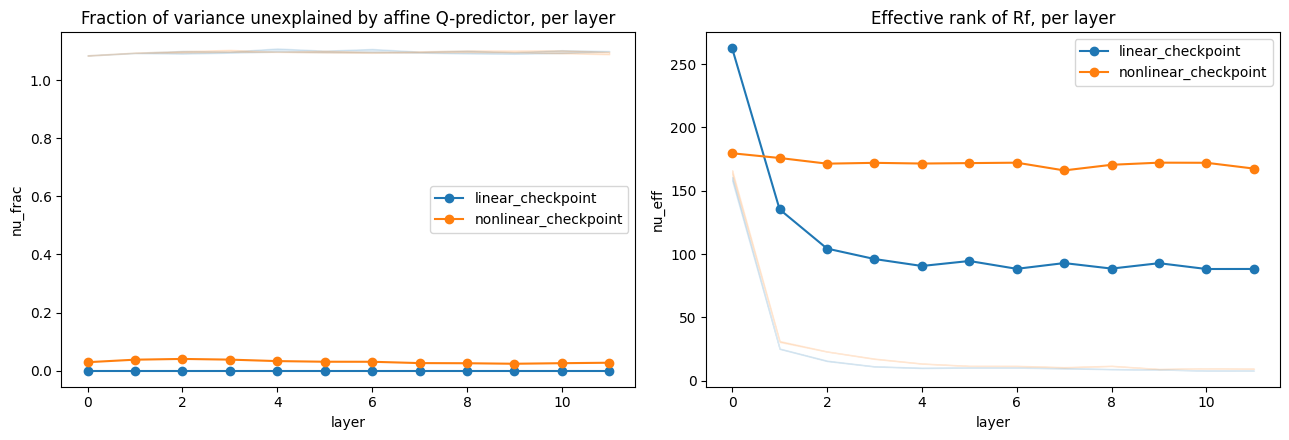

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ckpt_name, color in [("linear_checkpoint", "tab:blue"), ("nonlinear_checkpoint", "tab:orange")]:
    sub = df_layers[df_layers["checkpoint"] == ckpt_name]
    axes[0].plot(sub["layer"], sub["nu_frac"], marker="o", label=ckpt_name, color=color)
    axes[0].fill_between(sub["layer"],
                          sub["nu_frac_null_mean"] - sub["nu_frac_null_std"],
                          sub["nu_frac_null_mean"] + sub["nu_frac_null_std"],
                          color=color, alpha=0.15)
    axes[1].plot(sub["layer"], sub["nu_eff"], marker="o", label=ckpt_name, color=color)
    axes[1].fill_between(sub["layer"],
                          sub["nu_eff_null_mean"] - sub["nu_eff_null_std"],
                          sub["nu_eff_null_mean"] + sub["nu_eff_null_std"],
                          color=color, alpha=0.15)

axes[0].set_xlabel("layer"); axes[0].set_ylabel("nu_frac")
axes[0].set_title("Fraction of variance unexplained by affine Q-predictor, per layer")
axes[0].legend()

axes[1].set_xlabel("layer"); axes[1].set_ylabel("nu_eff")
axes[1].set_title("Effective rank of Rf, per layer")
axes[1].legend()

plt.tight_layout()
plt.show()

# shaded band = permutation-null mean +/- 1 std at that layer


In [1]:
"""
Run this in the SAME Kaggle/Colab notebook environment (or locally with gdown installed).
It walks the shared "Beyond Query Linearity" folder and prints, for each config subfolder,
the file id of its ckpt_50000.pt (or whichever checkpoint file is inside).

Usage:
    pip install gdown --quiet
    python list_drive_ckpts.py

Paste the printed dict back to Claude/Dun Li and it'll be wired straight into the notebook.
"""

import gdown
import re
import json

# The parent folder id, taken from the URL Pietro sent:
# https://drive.google.com/drive/folders/1JNlDCGk1Rw-kfsgmDBtLOkjl9iyGXCtt
PARENT_FOLDER_ID = "1JNlDCGk1Rw-kfsgmDBtLOkjl9iyGXCtt"

def list_folder(folder_id):
    """Returns list of dicts: {id, name, type} for immediate children of folder_id."""
    url = f"https://drive.google.com/drive/folders/{folder_id}"
    # gdown's download_folder can enumerate without downloading if we just want metadata,
    # but the simplest robust approach is gdown.download_folder(..., skip_download=True)
    items = gdown.download_folder(
        url=url,
        skip_download=True,
        quiet=True,
        use_cookies=False,
    )
    return items  # list of gdown.download_folder.GoogleDriveFileToDownload-like namedtuples (id, path)


def main():
    top_level = list_folder(PARENT_FOLDER_ID)
    if not top_level:
        print("Got nothing back — folder may need 'Anyone with link' sharing, or gdown version mismatch.")
        print("Try: pip install -U gdown")
        return

    # top_level items are (id, local_path) pairs mirroring the Drive structure.
    # We only want the actual checkpoint files, one level down inside each config folder.
    config_to_id = {}
    for item in top_level:
        # item.local_path something like: out_config_tiedw_residual_gelu/ckpt_50000.pt
        path = item.path if hasattr(item, "path") else item[1]
        file_id = item.id if hasattr(item, "id") else item[0]

        m = re.match(r"^([^/\\]+)[/\\](.+\.pt)$", path)
        if not m:
            continue
        config_name, filename = m.group(1), m.group(2)

        # Prefer ckpt_50000.pt if multiple checkpoints exist in a folder; else take whatever's there.
        if config_name not in config_to_id or filename == "ckpt_50000.pt":
            config_to_id[config_name] = {"file_id": file_id, "filename": filename}

    print(json.dumps(config_to_id, indent=2))


if __name__ == "__main__":
    main()

{
  "out_config_tiedw_original": {
    "file_id": "1zsdK2tTfrzuE5jL9p8YWaCah7uX-4x8f",
    "filename": "ckpt_50000.pt"
  },
  "out_config_tiedw_original_005wd": {
    "file_id": "1QEvEm55vKEIyhaq755oaZkpF3CJ-cf36",
    "filename": "ckpt.pt"
  },
  "out_config_tiedw_original_20k_steps": {
    "file_id": "1f1LungSE884IOAtWH_xGgjUCijN8zQhd",
    "filename": "ckpt.pt"
  },
  "out_config_tiedw_original_mlp_4_33_times": {
    "file_id": "1AyERlOwh6N2-qRigz2mhQCUQK05MTLXX",
    "filename": "ckpt_50000.pt"
  },
  "out_config_tiedw_original_mlp_4_5_times": {
    "file_id": "1OICQqm3p4uMKl36MzJpJS4ibeCweNFPx",
    "filename": "ckpt_50000.pt"
  },
  "out_config_tiedw_original_mlp_4_625_times": {
    "file_id": "13UnT0Xao3bJpbop6QUPJ1b_7NqTErjAQ",
    "filename": "ckpt_50000.pt"
  },
  "out_config_tiedw_original_mlp_4_75_times": {
    "file_id": "1IHJgnjzqB1kQMw5am9IAYhPGHZF70qR5",
    "filename": "ckpt_50000.pt"
  },
  "out_config_tiedw_original_mlp_4_75_times_lrscaled": {
    "file_id": "1VLv1Yt